# Generador de Gráficos 2.5 (Estandarizado Villa Gaucho)

Este cuaderno es una versión estandarizada de `generador_graficos 2_5.ipynb`, aplicando las especificaciones de diseño y formato del Informe de Villa Gaucho:
- **Tipografía y tamaño de letra 14**: configurado globalmente para títulos, etiquetas de ejes, valores y señalizaciones.
- **Gráficos de Torta (Cualitativas)**:
  - **Líneas blancas divisorias** entre las porciones de la torta (`edgecolor='white', linewidth=1.5`).
  - **Porcentajes adentro** de cada cuña (en negrita, tamaño 14, formato `X,X%`).
  - **Línea conectora con doblez en 2 tramos (diagonal + horizontal)**: arranca de un punto indicador en la cuña y finaliza justo donde comienza el texto, **sin subrayar**.
  - **Nombre de la categoría arriba** de la línea y **frecuencia absoluta con su unidad abajo** (`X hogares` o `X respuestas`).
  - Para preguntas binarias (ej. 2.5 indicador Sí / No): **Positivo = Azul (`#4285F4`)**, **Negativo = Naranja (`#FB8C00`)**.
  - Para razones/motivos múltiples: orden de mayor a menor porcentaje con la paleta de colores: 1. Azul (`#4285F4`), 2. Naranja (`#FB8C00`), 3. Verde (`#34A853`), 4. Amarillo (`#FBBC05`), 5. Violeta (`#8E24AA`), 6. Beige (`#D7CCC8`).
  - Distribución balanceada verticalmente en el recuadro para evitar superposiciones.


In [11]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN GLOBAL
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración global de tamaño de letra 14
plt.rcParams['font.size'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.titlesize'] = 14

# Paleta para tortas (de mayor a menor porcentaje)
PALETA_TORTA = [
    '#4285F4',  # 1. Azul
    '#FB8C00',  # 2. Naranja
    '#34A853',  # 3. Verde
    '#FBBC05',  # 4. Amarillo
    '#8E24AA',  # 5. Violeta
    '#D7CCC8'   # 6. Beige
]

# Colores para preguntas binarias (Positivo / Negativo)
COLOR_POSITIVO = '#4285F4'  # Azul
COLOR_NEGATIVO = '#FB8C00'  # Naranja


In [12]:
def graficar_torta(categorias, valores, titulo="", unidad="personas", es_binario=False, orden_positivo_primero=True, figsize=(10, 6), max_categorias_torta=5, conmutar_si_muchas_categorias=True, **kwargs):
    """
    Genera un gráfico de torta con el formato del Informe de Villa Gaucho:
    - Paleta ordenada de mayor a menor: Azul (#4285F4), Naranja (#FB8C00), Verde (#34A853), Amarillo (#FBBC05), Violeta (#8E24AA), Beige (#D7CCC8).
    - Si es binario (Sí/No): Positivo = Azul, Negativo = Naranja.
    - Porcentajes ADENTRO de la torta (en negrita, tamaño 14, formato X,X%).
    - Frecuencias absolutas AFUERA de la torta (debajo de la línea conectora con su unidad singular/plural).
    - Nombre de la categoría AFUERA de la torta (arriba de la línea conectora).
    - Líneas blancas divisorias entre porciones de la torta (edgecolor='white', linewidth=1.5).
    - Línea conectora en 2 tramos con codo (diagonal + horizontal) que arranca de un punto indicador en la cuña
      y finaliza exactamente donde comienza el texto de la categoría, sin subrayar.
    - Distribución vertical balanceada para evitar superposiciones entre categorías cercanas.
    - Si la variable posee más de 5 categorías y conmutar_si_muchas_categorias=True, conmuta automáticamente
      a un gráfico de barras horizontales con la paleta de torta.
    """
    df_temp = pd.DataFrame({'categoria': [str(c) for c in categorias], 'fi': list(valores)})

    # Conmutación automática si hay más de 5 categorías
    if conmutar_si_muchas_categorias and len(df_temp) > max_categorias_torta and not es_binario and 'graficar_barras_horizontales' in globals():
        print(f"[INFO] La variable tiene {len(df_temp)} categorías (> {max_categorias_torta}). Se grafica con barras horizontales usando la paleta de torta.")
        graficar_barras_horizontales(
            etiquetas=df_temp['categoria'],
            valores=df_temp['fi'],
            titulo=titulo,
            usar_colores_torta=True,
            ordenar_mayor_a_menor=True,
            figsize=(13, max(6, len(df_temp) * 0.8))
        )
        return

    # Asignación de colores y orden
    if es_binario:
        def es_pos(val):
            val_clean = str(val).strip().lower()
            return val_clean in ['si', 'sí', 'positivo', 'true', 'afirma', 'posee', 'tiene', 'concurre']

        df_temp['es_pos'] = df_temp['categoria'].apply(es_pos)
        if orden_positivo_primero:
            df_temp = df_temp.sort_values(by='es_pos', ascending=False).reset_index(drop=True)
        colores = [COLOR_POSITIVO if p else COLOR_NEGATIVO for p in df_temp['es_pos']]
    else:
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(df_temp))]

    cats = df_temp['categoria'].tolist()
    vals = df_temp['fi'].values

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(aspect="equal"))

    # Torta con líneas divisorias blancas y porcentajes adentro
    wedges, texts, autotexts = ax.pie(
        vals,
        autopct=lambda p: f"{p:.1f}%".replace('.', ','),
        pctdistance=0.72,
        colors=colores,
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=1, edgecolor='white', linewidth=1.5)
    )

    # Estilo porcentajes interiores (tamaño 14 y negrita)
    for at in autotexts:
        at.set_color('#1a1a1a')
        at.set_fontsize(14)
        at.set_fontweight('bold')

    # Calcular posiciones angulares y lados
    elementos = []
    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
        x = np.cos(np.deg2rad(ang))
        y = np.sin(np.deg2rad(ang))
        lado = -1 if x < 0 else 1

        elementos.append({
            'i': i,
            'x': x,
            'y': y,
            'lado': lado,
            'y_afuera': 1.15 * y
        })

    # Separación vertical balanceada para evitar solapamientos
    min_sep = 0.29
    y_min, y_max = -1.22, 1.24
    for lado_actual in (-1, 1):
        grupo = [e for e in elementos if e['lado'] == lado_actual]
        if len(grupo) <= 1:
            continue
        grupo.sort(key=lambda e: e['y_afuera'])
        for k in range(1, len(grupo)):
            if grupo[k]['y_afuera'] - grupo[k - 1]['y_afuera'] < min_sep:
                grupo[k]['y_afuera'] = grupo[k - 1]['y_afuera'] + min_sep
        if grupo[-1]['y_afuera'] > y_max:
            grupo[-1]['y_afuera'] = y_max
            for k in range(len(grupo) - 2, -1, -1):
                if grupo[k + 1]['y_afuera'] - grupo[k]['y_afuera'] < min_sep:
                    grupo[k]['y_afuera'] = grupo[k + 1]['y_afuera'] - min_sep
        if grupo[0]['y_afuera'] < y_min:
            ys = np.linspace(y_min, y_max, len(grupo))
            for k, e in enumerate(grupo):
                e['y_afuera'] = ys[k]

    # Líneas guía en 2 tramos (diagonal -> horizontal) que arrancan justo en el texto sin subrayar
    for e in elementos:
        i = e['i']
        x = e['x']
        y = e['y']
        lado = e['lado']
        y_afuera = e['y_afuera']

        # Punto sobre la cuña
        x_punto, y_punto = 0.85 * x, 0.85 * y
        x_afuera = 1.35 * lado

        # Codo donde la línea pasa de diagonal a horizontal (fuera del círculo)
        r_ext = 1.08 if abs(y_afuera - 1.15 * y) > 1e-6 else 1.15
        x_min_ext = np.sqrt(max(0.0, r_ext**2 - y_afuera**2))
        x_codo = lado * max(abs(1.15 * x), x_min_ext)
        y_codo = y_afuera

        # Fin de la recta horizontal dejando margen justo donde inicia el texto (sin subrayar)
        x_fin = x_afuera - 0.03 * lado

        # Punto gris indicador sobre la cuña
        ax.plot(x_punto, y_punto, marker='o', markersize=4, color='#8c8c8c', zorder=4)

        # Línea guía en 2 tramos: diagonal (punto -> codo) + horizontal (codo -> inicio del texto)
        ax.plot(
            [x_punto, x_codo, x_fin],
            [y_punto, y_codo, y_codo],
            color='#8c8c8c',
            lw=1.2,
            solid_joinstyle='round',
            zorder=2
        )

        # Formato de cantidad y unidad singular / plural
        cant = int(vals[i])
        if not unidad:
            texto_unidad = str(cant)
        elif cant == 1:
            if unidad.lower() == 'integrantes':
                palabra_unidad = 'integrante'
            elif unidad.lower() == 'hogares':
                palabra_unidad = 'hogar'
            elif unidad.lower() == 'personas':
                palabra_unidad = 'persona'
            elif unidad.endswith('es') and not unidad.endswith('tes'):
                palabra_unidad = unidad[:-2]
            elif unidad.endswith('s'):
                palabra_unidad = unidad[:-1]
            else:
                palabra_unidad = unidad
            texto_unidad = f"{cant} {palabra_unidad}"
        else:
            texto_unidad = f"{cant} {unidad}"

        alineacion_h = "right" if lado == -1 else "left"

        # 1. Nombre de la categoría ARRIBA de la línea
        ax.text(
            x_afuera,
            y_afuera + 0.015,
            cats[i],
            horizontalalignment=alineacion_h,
            verticalalignment="bottom",
            fontsize=14,
            color="#202124",
            fontweight='medium'
        )

        # 2. Frecuencia absoluta y unidad ABAJO de la línea
        ax.text(
            x_afuera,
            y_afuera - 0.035,
            texto_unidad,
            horizontalalignment=alineacion_h,
            verticalalignment="top",
            fontsize=14,
            color="#70757a"
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=20, fontweight='bold', color='#202124')

    ax.set_xlim(-1.95, 1.95)
    ax.set_ylim(-1.35, 1.35)
    plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
    plt.show()


## 3. Carga y Procesamiento de Datos


In [13]:
# ==============================================================================
# CARGA Y PROCESAMIENTO DE DATOS - PREGUNTA 2.5
# ==============================================================================
# Cargar el archivo CSV y limpiar espacios en los nombres de columnas
df = pd.read_csv('datos.csv')
df.columns = df.columns.str.strip()

col_motivo = '2.5 En caso de que algún integrante no realice todas las comidas, ¿a qué se debe? Indicar la respuesta de manera que pueda identificarse según el integrante. Ejemplo: Int. 1 (motivo) - Int. 2 (motivo) Definido'
col_motivo_raw = '2.5 En caso de que algún integrante no realice todas las comidas, ¿a qué se debe? Indicar la respuesta de manera que pueda identificarse según el integrante. Ejemplo: Int. 1 (motivo) - Int. 2 (motivo)'

# Dataset base y variable indicadora binaria ('Si' / 'No' a nivel de hogar)
df_2_5_combinado = df[[col_motivo]].copy()
df_2_5_combinado = df_2_5_combinado.rename(columns={col_motivo: 'Motivo'})
df_2_5_combinado['Tiene_motivo'] = np.where(df_2_5_combinado['Motivo'].notna(), 'Si', 'No')

# Frecuencia de la variable indicadora binaria (hogares)
df_2_5_indicadorfi = df_2_5_combinado['Tiene_motivo'].value_counts().to_frame(name='fi')

# Dataset solo con motivos reportados
df_2_5_razones = df_2_5_combinado[df_2_5_combinado['Tiene_motivo'] == 'Si'][['Motivo']].reset_index(drop=True)

# ==============================================================================
# CONTEO POR INTEGRANTE
# ==============================================================================
# Cada respuesta de hogar contiene uno o más integrantes especificados
# (ej: 'int. 1 preferencia - int. 2 escuela-trabajo - int. 3 escuela-trabajo').
# Para contabilizar cada integrante de forma individual, desglosamos las respuestas.

import re

# Parámetro para seleccionar el esquema de categorías:
# - False (por defecto): 4 categorías estándar de la columna definida
#   ('Escuela / Trabajo', 'Preferencia Personal', 'Motivos Económicos', 'Salud y Dieta').
# - True: 5 categorías separando 'Trabajo' (16 int.) y 'Escuela' (2 int.) según lo reportado.
SEPARAR_ESCUELA_TRABAJO = False

if not SEPARAR_ESCUELA_TRABAJO:
    # 4 categorías estándar según la base definida
    razones_map = {
        'escuela-trabajo': 'Escuela / Trabajo',
        'preferencia': 'Preferencia Personal',
        'motivos economicos': 'Motivos Económicos',
        'salud-dieta': 'Salud y Dieta'
    }

    conteos = {nombre_limpio: 0 for nombre_limpio in razones_map.values()}

    for motivo_str in df_2_5_razones['Motivo'].dropna():
        # Separar por el delimitador entre integrantes (' - ')
        partes = re.split(r'\s+-\s+', str(motivo_str).strip())
        for parte in partes:
            p_clean = parte.strip().lower()
            for clave, nombre_limpio in razones_map.items():
                if clave in p_clean:
                    conteos[nombre_limpio] += 1
                    break
else:
    # 5 categorías separando 'Trabajo' y 'Escuela'
    conteos = {
        'Trabajo': 0,
        'Preferencia Personal': 0,
        'Motivos Económicos': 0,
        'Salud y Dieta': 0,
        'Escuela': 0
    }
    for idx, row in df.iterrows():
        val_def = row[col_motivo]
        val_raw = row[col_motivo_raw]
        if pd.isna(val_def):
            continue
        partes = re.split(r'\s+-\s+', str(val_def).strip())
        for p in partes:
            p_lower = p.strip().lower()
            if 'motivos economicos' in p_lower:
                conteos['Motivos Económicos'] += 1
            elif 'salud-dieta' in p_lower:
                conteos['Salud y Dieta'] += 1
            elif 'preferencia' in p_lower:
                conteos['Preferencia Personal'] += 1
            elif 'escuela-trabajo' in p_lower:
                if 'escuela' in str(val_raw).lower() and ('int 2-3' in str(val_raw).lower() or 'int 2' in p_lower or 'int.3' in p_lower):
                    if 'int. 1' in p_lower or 'int 1' in p_lower:
                        conteos['Trabajo'] += 1
                    else:
                        conteos['Escuela'] += 1
                else:
                    conteos['Trabajo'] += 1

df_2_5_estandarizado = pd.DataFrame(list(conteos.items()), columns=['Razon', 'fi'])
print("=== CONTEO DE MOTIVOS POR INTEGRANTE ===")
print(df_2_5_estandarizado)
print(f"Total integrantes: {df_2_5_estandarizado['fi'].sum()}")


=== CONTEO DE MOTIVOS POR INTEGRANTE ===
                  Razon  fi
0     Escuela / Trabajo  18
1  Preferencia Personal  11
2    Motivos Económicos   6
3         Salud y Dieta   3
Total integrantes: 38


## 4. Pregunta 2.5: Hogares con motivos para no realizar todas las comidas


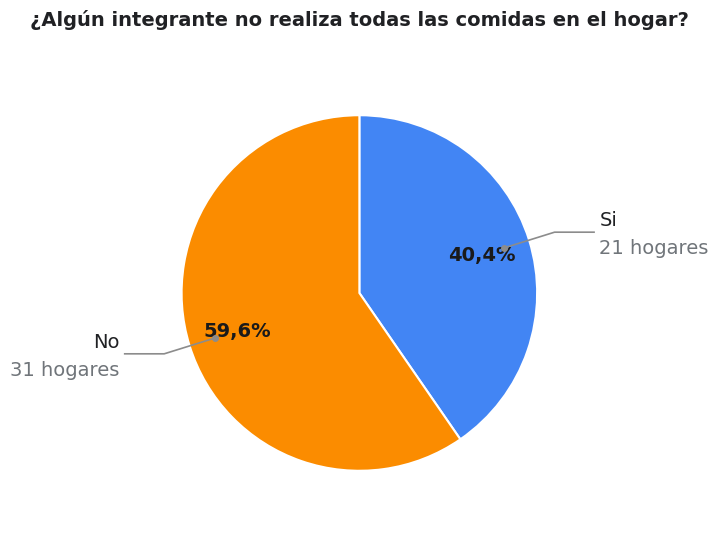

In [14]:
# Gráfico de torta: Pregunta binaria Sí / No (Positivo = Azul, Negativo = Naranja)
graficar_torta(
    categorias=df_2_5_indicadorfi.index,
    valores=df_2_5_indicadorfi['fi'],
    titulo="¿Algún integrante no realiza todas las comidas en el hogar?",
    es_binario=True , # Positivo = Azul, Negativo = Naranja
    unidad="hogares"
)


## 5. Pregunta 2.5: Motivos reportados


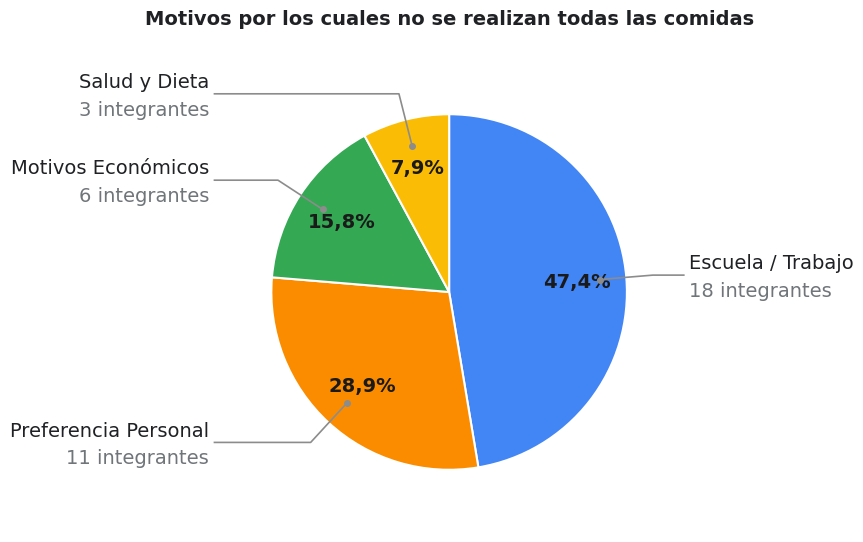

In [15]:
# Gráfico de torta: Distribución de motivos por integrante (Variable Cualitativa Multicategoría)
graficar_torta(
    categorias=df_2_5_estandarizado['Razon'],
    valores=df_2_5_estandarizado['fi'],
    titulo="Motivos por los cuales no se realizan todas las comidas",
    unidad="integrantes"
)
